In [1]:
# import pandas 
import pandas as pd
# import numpy
import numpy as np
# import matplotlib
from matplotlib import pyplot as plt
# make plots appear and be stored within the notebook
%matplotlib inline

# 1. Significant earthquakes since 2150 B.C.

In [2]:
# 读取Sig_Eqs.tsv文件
SE = pd.read_csv("Sig_Eqs.tsv", sep="\t", skiprows=[1])
SE = SE.drop(columns=["Search Parameters"]).reset_index(drop=True)
SE.head(10)

,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,Country,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
0,1,-2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,JORDAN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,-2000,NaN,NaN,NaN,NaN,NaN,1.0,NaN,SYRIA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,-2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TURKMENISTAN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN
3,5877,-1610,NaN,NaN,NaN,NaN,NaN,3.0,1351.0,GREECE,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
4,8,-1566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ISRAEL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,11,-1450,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ITALY,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,9712,-1365,NaN,NaN,NaN,NaN,NaN,4.0,NaN,SYRIA,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
7,12,-1250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ISRAEL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,13,-1050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,JORDAN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,14,-759,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ISRAEL,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN


In [3]:
# 1.1
top20_deaths = SE[SE["Year"] >= -2150].groupby(["Country"])["Deaths"].sum().sort_values(ascending=False)

print("公元前2150年以来地震死亡人数前20国家：")
top20_deaths.head(20)

公元前2150年以来地震死亡人数前20国家：


Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014453.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64

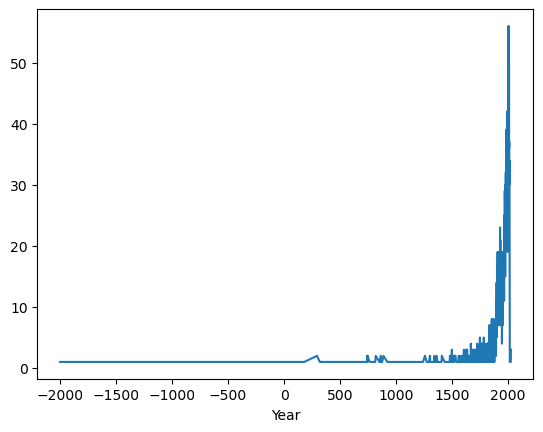

In [4]:
# 1.2
over3_Ms = SE[SE["Ms"] > 3.0].groupby(["Year"]).count()["Ms"].plot()

plt.show()

In [5]:
# 1.3
def CountEq_LargestEq(country_name):
    bf2150_ct = (SE["Country"] == country_name) & (SE["Year"] >= -2150)
    country_data = SE[bf2150_ct].copy()
    
    eq_count = len(country_data)
    
    if eq_count == 0:
        return eq_count, "无记录", "无记录"
    
    # ========== 先去掉震级为空的行，再找最大值 ==========
    valid_data = country_data.dropna(subset=["Ms"])
    if len(valid_data) == 0:
        return eq_count, "无有效震级记录", "无记录"
    # ==========================================================
    
    largest_eq = country_data.loc[country_data["Ms"].idxmax()]
    date_str = f"{int(largest_eq['Year'])}年"
    if pd.notnull(largest_eq["Mo"]):
        date_str += f"{int(largest_eq['Mo'])}月"
    if pd.notnull(largest_eq["Dy"]):
        date_str += f"{int(largest_eq['Dy'])}日"
    location = largest_eq["Location Name"]
    
    return eq_count, date_str, location

count, date, loc = CountEq_LargestEq("CHINA")
print(f"中国地震总数：{count}")
print(f"最大地震日期：{date}")
print(f"最大地震位置：{loc}")

中国地震总数：626
最大地震日期：1920年12月16日
最大地震位置：CHINA:  GANSU PROVINCE, SHANXI PROVINCE


In [6]:
countries = SE["Country"].unique()

result_list = []
for country in countries:
    cnt, eq_date, eq_loc = CountEq_LargestEq(country)
    result_list.append({
        "Country": country,
        "Total_Earthquakes": cnt,
        "Largest_Eq_Date": eq_date,
        "Largest_Eq_Location": eq_loc
    })

result_df = pd.DataFrame(result_list).sort_values(
    by="Total_Earthquakes", 
    ascending=False
).reset_index(drop=True)

print(result_df.head(20))

             Country  Total_Earthquakes Largest_Eq_Date  \
0              CHINA                626     1920年12月16日   
1              JAPAN                429       869年7月13日   
2          INDONESIA                427     2004年12月26日   
3               IRAN                385      856年12月22日   
4             TURKEY                359     1939年12月26日   
5              ITALY                338      1915年1月13日   
6             GREECE                296       365年7月21日   
7                USA                283       1957年3月9日   
8        PHILIPPINES                233      1897年9月21日   
9             MEXICO                217      1787年3月28日   
10             CHILE                200       1730年7月8日   
11              PERU                195      1619年2月14日   
12            RUSSIA                159      1952年11月4日   
13  PAPUA NEW GUINEA                107     2000年11月16日   
14            TAIWAN                103       1920年6月5日   
15             INDIA                102      1897年6月12日 

# 2. Air temperature in Shenzhen 1998-2022

In [7]:
# 1.读取数据
df = pd.read_csv("Baoan_Weather_1998_2022.csv", low_memory=False)
df.columns = df.columns.str.strip()
df.head(10)

,STATION,DATE,SOURCE,REPORT_TYPE,CALL_SIGN,QUALITY_CONTROL,AA1,AA2,AA3,AG1,...,REPORT_TYPE.1,SA1,SLP,SOURCE.1,TMP,UA1,UG1,VIS,WG1,WND
0,59493099999,1998-01-01T00:00:00,4,SY-MT,ZGSZ,V020,"06,0000,9,1",NaN,NaN,"0,000",...,SY-MT,NaN,"10184,1",4,"+0186,1",NaN,NaN,"008000,1,N,1",NaN,"040,1,N,0040,1"
1,59493099999,1998-01-01T01:00:00,4,FM-15,ZGSZ,V020,NaN,NaN,NaN,"0,999",...,FM-15,NaN,"99999,9",4,"+0220,1",NaN,NaN,"003300,1,N,1",NaN,"130,1,N,0020,1"
2,59493099999,1998-01-01T02:00:00,4,FM-15,ZGSZ,V020,NaN,NaN,NaN,"0,999",...,FM-15,NaN,"99999,9",4,"+0240,1",NaN,NaN,"003500,1,N,1",NaN,"110,1,N,0020,1"
3,59493099999,1998-01-01T03:00:00,4,SY-MT,ZGSZ,V020,NaN,NaN,NaN,"0,000",...,SY-MT,NaN,"10185,1",4,"+0221,1",NaN,NaN,"011000,1,N,1",NaN,"090,1,N,0020,1"
4,59493099999,1998-01-01T04:00:00,4,FM-15,ZGSZ,V020,NaN,NaN,NaN,"0,999",...,FM-15,NaN,"99999,9",4,"+0240,1",NaN,NaN,"005000,1,N,1",NaN,"270,1,N,0030,1"
5,59493099999,1998-01-01T05:00:00,4,FM-15,ZGSZ,V020,NaN,NaN,NaN,"0,999",...,FM-15,NaN,"99999,9",4,"+0240,1",NaN,NaN,"001800,1,N,1",NaN,"310,1,N,0040,1"
6,59493099999,1998-01-01T06:00:00,4,SY-MT,ZGSZ,V020,"06,0000,9,1",NaN,NaN,"0,000",...,SY-MT,NaN,"10154,1",4,"+0254,1",NaN,NaN,"011000,1,N,1",NaN,"020,1,N,0020,1"
7,59493099999,1998-01-01T07:00:00,4,FM-15,ZGSZ,V020,NaN,NaN,NaN,"0,999",...,FM-15,NaN,"99999,9",4,"+0250,1",NaN,NaN,"006000,1,N,1",NaN,"280,1,N,0030,1"
8,59493099999,1998-01-01T08:00:00,4,FM-15,ZGSZ,V020,NaN,NaN,NaN,"0,999",...,FM-15,NaN,"99999,9",4,"+0250,1",NaN,NaN,"009900,1,N,1",NaN,"290,1,N,0030,1"
9,59493099999,1998-01-01T09:00:00,4,SY-MT,ZGSZ,V020,NaN,NaN,NaN,"0,000",...,SY-MT,NaN,"10160,1",4,"+0253,1",NaN,NaN,"012000,1,N,1",NaN,"340,1,N,0010,1"


有效气温记录数： 234877
月均温前5条：
DATE
1998-01-01    15.233447
1998-02-01    16.875304
1998-03-01    19.971246
1998-04-01    25.228365
1998-05-01    27.098454
Freq: MS, Name: TMP, dtype: float64


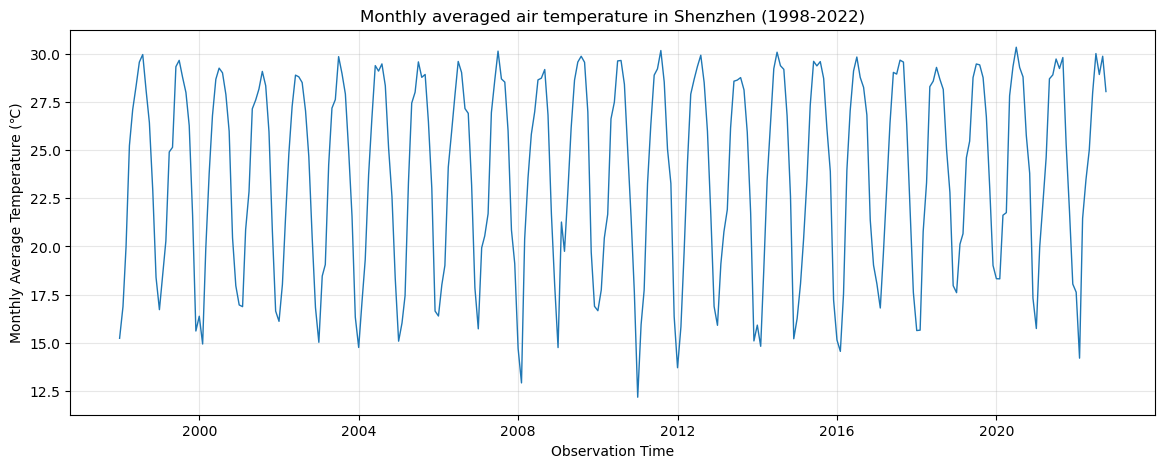

In [8]:
# 2.提取有效气温值
df["tmp_part"] = df["TMP"].astype(str).str.split(",").str[0]
df["TMP"] = pd.to_numeric(df["tmp_part"], errors="coerce")

df_clean = df[df["TMP"] != 9999].copy()
df_clean["TMP"] = df_clean["TMP"] / 10

# 3.时间解析
df_clean["DATE"] = pd.to_datetime(df_clean["DATE"], errors="coerce")
df_clean = df_clean.dropna(subset=["DATE"])
df_clean = df_clean.set_index("DATE")

# 4.按月重采样计算月均温
monthly_temp = df_clean["TMP"].resample("MS").mean()

print("有效气温记录数：", len(df_clean))
print("月均温前5条：")
print(monthly_temp.head())

# 5.绘图
plt.figure(figsize=(14, 5))
plt.plot(monthly_temp.index, monthly_temp.values, linewidth=1)
plt.title("Monthly averaged air temperature in Shenzhen (1998-2022)")
plt.xlabel("Observation Time")
plt.ylabel("Monthly Average Temperature (℃)")
plt.grid(alpha=0.3)
plt.show()

# 3. Global collection of hurricanes

In [9]:
storms = pd.read_csv(
    "ibtracs.ALL.list.v04r00.csv",
    usecols=range(17),
    skiprows=[1],
    parse_dates=["ISO_TIME"],
    na_values=["NOT_NAMED", "NAME"],
    low_memory=False
)

storms.head(5)

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 03:00:00,NR,10.9000,80.3000,,,,main,43,0,__________O___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,,,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,,,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,,,,main,0,0,__________P___
4,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,,,,main,0,0,__________O___


In [10]:
# 3.1
storms_valid = storms.dropna(subset=["WMO_WIND"])

storm_maxwind = storms_valid.groupby("SID").agg(
    max_wind=("WMO_WIND", "max"),
    storm_name=("NAME", "first")
).reset_index()

top10_storms = storm_maxwind.sort_values("max_wind", ascending=False).head(10)
print("Top 10 hurricane names:")
print(top10_storms["storm_name"])

Top 10 hurricane names:
11015            RHONDA
11909             TALIM
11865             PERCY
11867            INGRID
11872    ADELINE:JULIET
11877             NESAT
11887             EMILY
11888           HAITANG
11905             MAWAR
11908           KATRINA
Name: storm_name, dtype: object


In [11]:
# 3.2
top20_storms = storm_maxwind.sort_values("max_wind", ascending=False).head(20)
print("Wind speed of top20 hurricanes:")
print(top20_storms["max_wind"])

Wind speed of top20 hurricanes:
11015    95
11909    95
11865    95
11867    95
11872    95
11877    95
11887    95
11888    95
11905    95
11908    95
2182     95
11912    95
11977    95
2175     95
11918    95
2164     95
11927    95
11931    95
11941    95
11944    95
Name: max_wind, dtype: object


In [12]:
# 3.3
basin_count = storms.groupby("BASIN").size()
print("Count by Basin:")
print(basin_count)

Count by Basin:
BASIN
EP     62412
NI     55402
SA       119
SI    160668
SP     67119
WP    236576
dtype: int64


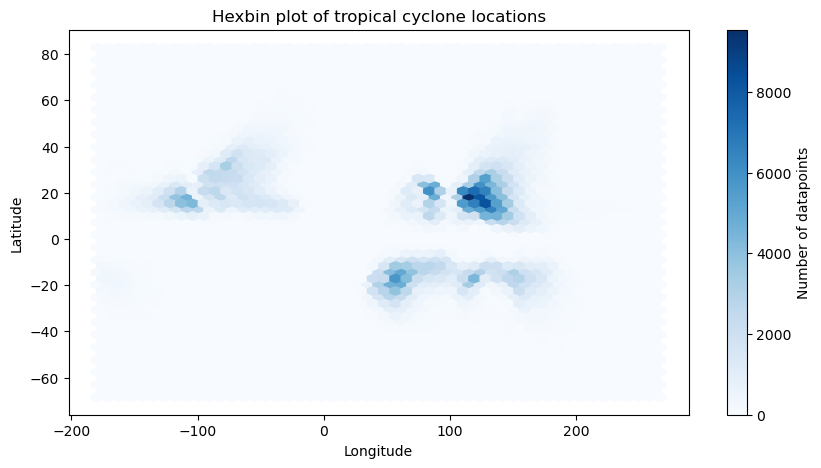

In [13]:
# 3.4
plt.figure(figsize=(10,5))
plt.hexbin(storms["LON"], storms["LAT"], gridsize=50, cmap="Blues")
plt.colorbar(label="Number of datapoints")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Hexbin plot of tropical cyclone locations")
plt.show()

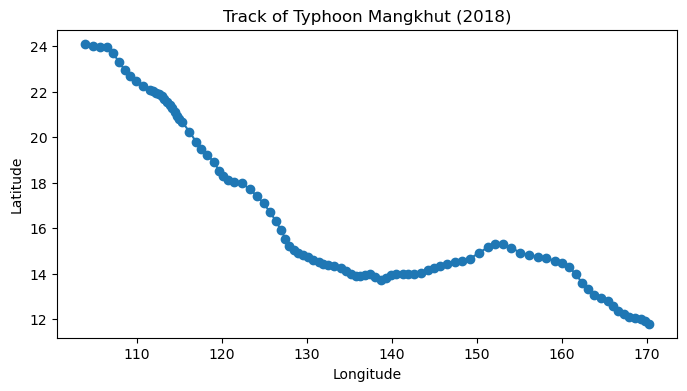

In [14]:
# 3.5
mangkhut = storms[(storms["NAME"] == "MANGKHUT") & (storms["SEASON"] == 2018)]
plt.figure(figsize=(8,4))
plt.plot(mangkhut["LON"], mangkhut["LAT"], marker="o")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Track of Typhoon Mangkhut (2018)")
plt.show()

In [15]:
# 3.6
storms_filtered = storms[
    (storms["ISO_TIME"] >= "1970-01-01") &
    (storms["BASIN"].isin(["WP", "EP"]))
].copy()
storms_filtered.head(5)

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
350394,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 00:00:00,TS,7.00000,151.400,,1006,tokyo,main,1088,1088,_OO___________
350395,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 03:00:00,TS,7.24752,151.205,,,,main,1109,1109,_PP___________
350396,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 06:00:00,TS,7.50000,151.000,,1002,tokyo,main,1143,1143,_OO___________
350397,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 09:00:00,TS,7.75747,150.772,,,,main,1171,1168,_PP___________
350398,1970050N07151,1970,22,WP,MM,NANCY,1970-02-19 12:00:00,TS,8.00000,150.500,,998,tokyo,main,1182,1179,_OO___________


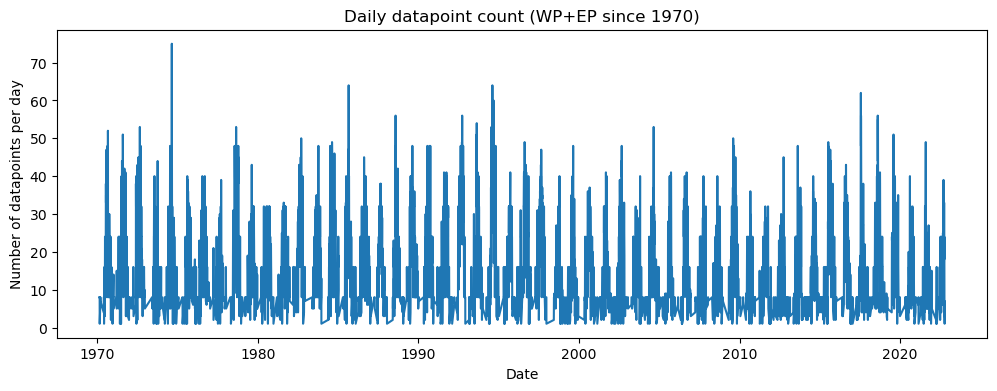

In [16]:
# 3.7
storms_filtered["date"] = storms_filtered["ISO_TIME"].dt.date
daily_count = storms_filtered.groupby("date").size()

plt.figure(figsize=(12,4))
daily_count.plot()
plt.xlabel("Date")
plt.ylabel("Number of datapoints per day")
plt.title("Daily datapoint count (WP+EP since 1970)")
plt.show()

In [17]:
# 3.8
storms_filtered["dayofyear"] = storms_filtered["ISO_TIME"].dt.dayofyear

daily_count_df = storms_filtered.groupby(["date", "dayofyear"]).size().reset_index(name="count")

climatology = daily_count_df.groupby("dayofyear")["count"].mean()
print("Climatology (day of year mean count):")
print(climatology.head())

Climatology (day of year mean count):
dayofyear
1    7.545455
2    8.000000
3    6.727273
4    7.750000
5    8.750000
Name: count, dtype: float64


In [18]:
# 3.9
# 气候态转成字典
clim_dict = climatology.to_dict()
daily_count_df["count_clim"] = daily_count_df["dayofyear"].map(clim_dict)
# 距平 = 实际值 - 气候平均值
daily_count_df["anomaly"] = daily_count_df["count"] - daily_count_df["count_clim"]

print("Daily anomaly example:")
print(daily_count_df[["date", "dayofyear", "count", "count_clim", "anomaly"]].head())

Daily anomaly example:
         date  dayofyear  count  count_clim   anomaly
0  1970-02-19         50      8    6.500000  1.500000
1  1970-02-20         51      8    8.000000  0.000000
2  1970-02-21         52      8    7.166667  0.833333
3  1970-02-22         53      8    6.600000  1.400000
4  1970-02-23         54      8    5.400000  2.600000


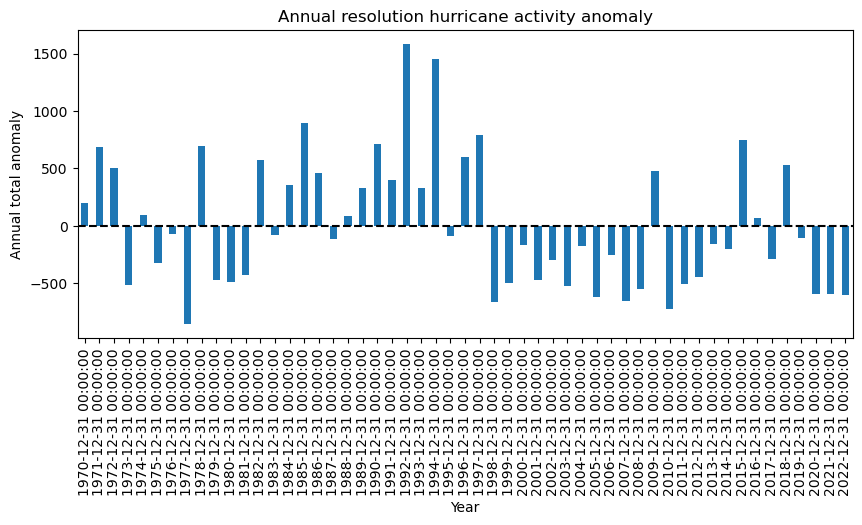

In [19]:
# 3.10
daily_count_df["date_dt"] = pd.to_datetime(daily_count_df["date"])
daily_anomaly_ts = daily_count_df.set_index("date_dt")["anomaly"]

annual_anomaly = daily_anomaly_ts.resample("Y").sum()

plt.figure(figsize=(10,4))
annual_anomaly.plot(kind="bar")
plt.axhline(y=0, color="k", linestyle="--")
plt.xlabel("Year")
plt.ylabel("Annual total anomaly")
plt.title("Annual resolution hurricane activity anomaly")
plt.show()

# 4. Explore a data set

In [20]:
us_temp = pd.read_csv(
    "us_monthly_temp.csv",
    skiprows=2,
    na_values=[-99, -999]
)

us_temp["Date"] = pd.to_datetime(us_temp["Date"].astype(str), format="%Y%m")
ts = us_temp.set_index("Date")

ts_clean = ts.dropna(subset=["Value"])

ts_clean["Temp_C"] = (ts_clean["Value"] - 32) * 5 / 9

print(f"清洗完成：有效记录 {len(ts_clean)} 条")
print(f"时间范围：{ts_clean.index.min().year} ~ {ts_clean.index.max().year}")

清洗完成：有效记录 132 条
时间范围：1895 ~ 2026


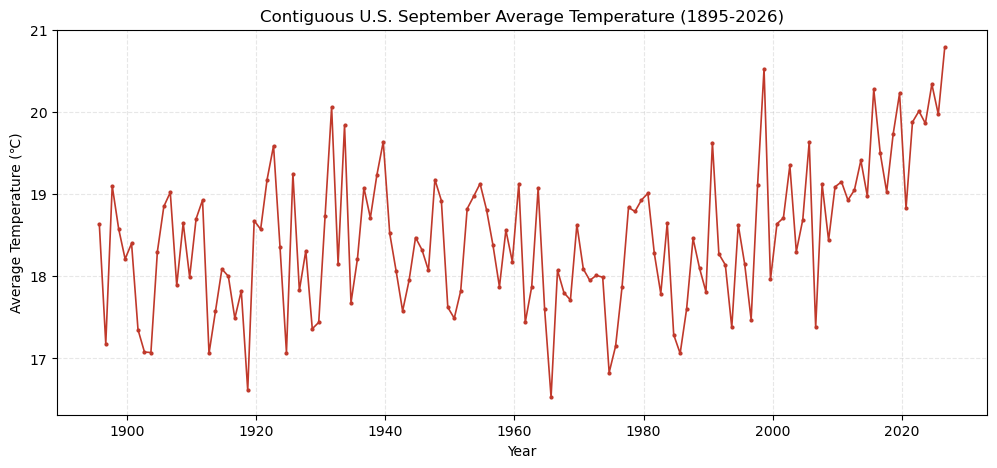

In [21]:
# 4.2
plt.figure(figsize=(12, 5))
plt.plot(ts_clean.index, ts_clean["Temp_C"], color="#c0392b", linewidth=1.2, marker=".", markersize=4)
plt.title("Contiguous U.S. September Average Temperature (1895-2026)")
plt.xlabel("Year")
plt.ylabel("Average Temperature (℃)")
plt.grid(alpha=0.3, linestyle="--")
plt.show()

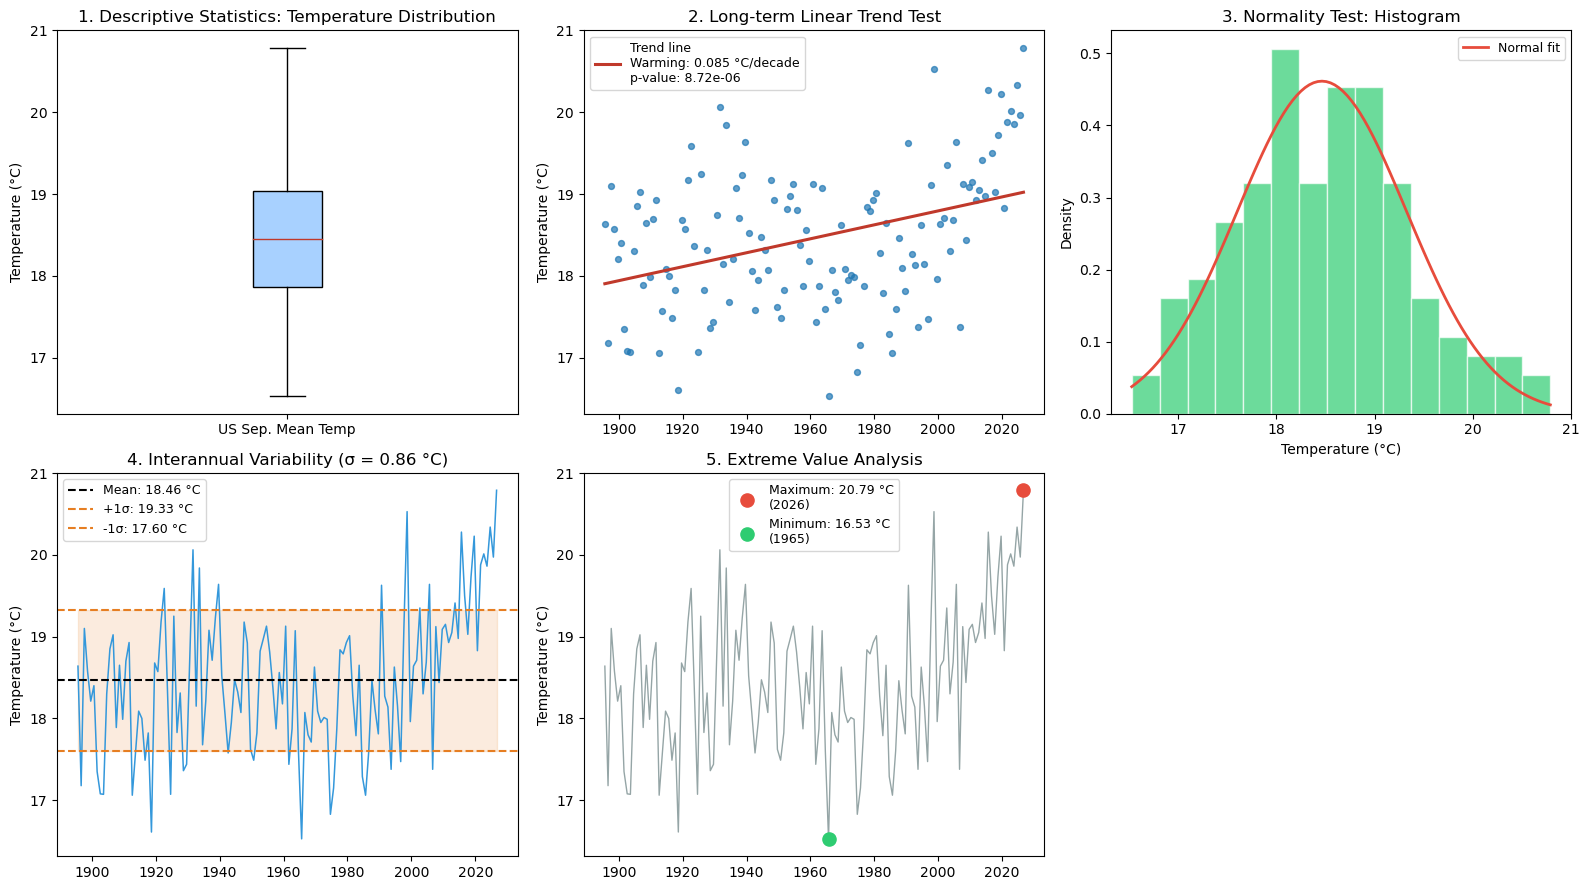

In [22]:
# 4.3 
from scipy.stats import linregress, norm

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
temp_data = ts_clean["Temp_C"].values

# 1. Descriptive statistics: boxplot
axes[0].boxplot(temp_data, patch_artist=True,
                boxprops=dict(facecolor="#a8d1ff"),
                medianprops=dict(color="#c0392b"))
axes[0].set_title("1. Descriptive Statistics: Temperature Distribution")
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_xticks([1], ["US Sep. Mean Temp"])

# 2. Linear trend test
x_num = np.arange(len(temp_data))
slope, intercept, r, p, se = linregress(x_num, temp_data)
y_fit = intercept + slope * x_num

axes[1].scatter(ts_clean.index, temp_data, s=18, alpha=0.7, color="#1f77b4")
axes[1].plot(ts_clean.index, y_fit, color="#c0392b", linewidth=2.2,
             label=f"Trend line\nWarming: {slope*10:.3f} °C/decade\np-value: {p:.2e}")
axes[1].set_title("2. Long-term Linear Trend Test")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend(fontsize=9)

# 3. Normality test: histogram + normal fit
mu, std = temp_data.mean(), temp_data.std()
axes[2].hist(temp_data, bins=15, density=True, alpha=0.7,
             color="#2ecc71", edgecolor="white")
x_norm = np.linspace(temp_data.min(), temp_data.max(), 100)
y_norm = norm.pdf(x_norm, mu, std)
axes[2].plot(x_norm, y_norm, color="#e74c3c", linewidth=2, label="Normal fit")
axes[2].set_title("3. Normality Test: Histogram")
axes[2].set_xlabel("Temperature (°C)")
axes[2].set_ylabel("Density")
axes[2].legend(fontsize=9)

# 4. Interannual variability: mean ± std band
axes[3].plot(ts_clean.index, temp_data, color="#3498db", linewidth=1.1)
axes[3].axhline(mu, color="black", linestyle="--", label=f"Mean: {mu:.2f} °C")
axes[3].axhline(mu + std, color="#e67e22", linestyle="--", label=f"+1σ: {mu+std:.2f} °C")
axes[3].axhline(mu - std, color="#e67e22", linestyle="--", label=f"-1σ: {mu-std:.2f} °C")
axes[3].fill_between(ts_clean.index, mu-std, mu+std, alpha=0.15, color="#e67e22")
axes[3].set_title(f"4. Interannual Variability (σ = {std:.2f} °C)")
axes[3].set_ylabel("Temperature (°C)")
axes[3].legend(fontsize=9)

# 5. Extreme values: mark max & min
max_date = ts_clean["Temp_C"].idxmax()
min_date = ts_clean["Temp_C"].idxmin()
max_val = temp_data.max()
min_val = temp_data.min()

axes[4].plot(ts_clean.index, temp_data, color="#95a5a6", linewidth=1)
axes[4].scatter(max_date, max_val, color="#e74c3c", s=90, zorder=5,
                label=f"Maximum: {max_val:.2f} °C\n({max_date.year})")
axes[4].scatter(min_date, min_val, color="#2ecc71", s=90, zorder=5,
                label=f"Minimum: {min_val:.2f} °C\n({min_date.year})")
axes[4].set_title("5. Extreme Value Analysis")
axes[4].set_ylabel("Temperature (°C)")
axes[4].legend(fontsize=9)

axes[5].axis("off")

plt.tight_layout()
plt.show()